# 04 · ¿Se ve el estrés en la fisiología? Marcadores por condición

**Capítulo 1 — Bloques G (marcadores), H (variabilidad entre sujetos) e I (concordancia entre sensores) del EDA**

Este es el notebook que responde el **objetivo específico 1**: identificar qué señales aportan más a la
detección del estrés.

## ¿Qué hace este notebook?
1. Resume cada señal con **marcadores fisiológicos conocidos** por sujeto y condición
   (p. ej. frecuencia cardíaca, RMSSD, nivel de sudoración, frecuencia respiratoria).
2. Prueba si los marcadores **cambian entre condiciones** con pruebas estadísticas pareadas.
3. Mide cuánto **difieren las personas entre sí** (justifica normalizar por sujeto).
4. Compara sensores que miden lo mismo: **ECG vs. BVP** (frecuencia cardíaca) y **EDA pecho vs. muñeca**.

## Qué esperamos según la literatura (estrés agudo)
| Marcador | Dirección esperada en estrés | Por qué |
|---|---|---|
| Frecuencia cardíaca (FC) | ↑ | activación simpática |
| RMSSD, pNN50 | ↓ | retirada del sistema parasimpático (vago) |
| SCL (nivel de EDA) y SCR por minuto | ↑ | sudoración por activación simpática |
| Frecuencia respiratoria | ↑ | activación; además en WESAD se habla durante el estrés |
| Temperatura de la muñeca | ↓ | vasoconstricción periférica |

In [1]:
import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wesad_pre import config as cfg
from wesad_pre import carga, etiquetas, calidad, limpieza, eventos, procesamiento, marcadores, estadistica, ventanas
from wesad_pre import graficas as gr

warnings.filterwarnings("ignore")
gr.setup()
pd.set_option("display.max_columns", 50, "display.width", 200)

DATA_PATH = os.path.join("..", "WESAD")   # carpeta con S2/, S3/, ... (ajústala si los datos están en otro lugar)
SUBJECTS = cfg.SUBJECT_IDS
os.makedirs(cfg.OUT_DIRS["tables"], exist_ok=True)

## 1. Marcadores por sujeto y condición
Se calculan a partir de las señales limpias y los eventos del notebook 03 (no hace falta volver a cargar los `.pkl`).

In [2]:
markers = pd.concat([marcadores.subject_markers(procesamiento.load_processed(sid)) for sid in SUBJECTS],
                    ignore_index=True)
markers.to_csv(os.path.join(cfg.OUT_DIRS["tables"], "marcadores_por_condicion.csv"), index=False)
tabla = markers.pivot_table(index=["señal", "marcador", "unidad"], columns="condicion", values="valor", aggfunc="median")
tabla[cfg.COND_ORDER].round(2)

condicion                                         baseline  stress  amusement  meditation
señal      marcador                       unidad                                         
chest_ACC  Índice de movimiento           g           0.00    0.01       0.01        0.00
chest_ECG  % intervalos válidos           %         100.00  100.00     100.00      100.00
           FC                             lpm        70.79   89.72      74.16       69.43
           RMSSD                          ms         48.70   38.87      42.41       64.82
           SDNN                           ms         71.20   71.31      76.53      103.58
           pNN50                          %          27.98   15.23      17.69       28.69
chest_EDA  Amplitud SCR                   µS          0.03    0.14       0.03        0.03
           SCL                            µS          2.81    3.93       3.11        3.47
           SCR por minuto                 1/min       0.30    2.98       1.13        0.68
chest_EMG  RMS de EMG                     mV          0.01    0.01       0.01        0.01
chest_Resp Amplitud respiratoria          u.a.        6.67   10.89       6.96        9.21
           Frecuencia respiratoria        rpm        16.87   15.65      17.37       10.09
           Variabilidad respiratoria (CV)             0.26    0.43       0.36        0.31
chest_Temp Pendiente de temperatura       °C/min      0.02    0.02       0.01        0.00
           Temperatura media              °C         33.71   34.35      34.22       34.20
wrist_ACC  Índice de movimiento           g           0.02    0.04       0.01        0.01
wrist_BVP  % intervalos válidos           %          77.24   58.65      65.19       73.70
           FC                             lpm        71.61   80.52      70.50       69.51
           RMSSD                          ms        192.47  283.71     186.18      158.93
           SDNN                           ms        159.49  228.14     153.30      159.80
           pNN50                          %          60.46   73.97      62.61       57.46
wrist_EDA  Amplitud SCR                   µS          0.11    0.18       0.05        0.05
           SCL                            µS          0.40    2.20       0.44        0.48
           SCR por minuto                 1/min       0.31    3.97       0.82        0.23
wrist_TEMP Pendiente de temperatura       °C/min      0.02   -0.07      -0.02       -0.01
           Temperatura media              °C         33.65   32.90      32.77       32.08

## 2. Los marcadores de las 10 señales, sujeto por sujeto
**Cómo leer cada panel:** cada línea gris es un sujeto recorriendo las 4 condiciones; los puntos de color y la línea
negra son la mediana. Si la mayoría de las líneas grises suben (o bajan) al pasar a "Estrés", el marcador
responde al estrés de forma **consistente entre personas**, que es lo que necesita un modelo que generalice a
sujetos nuevos.

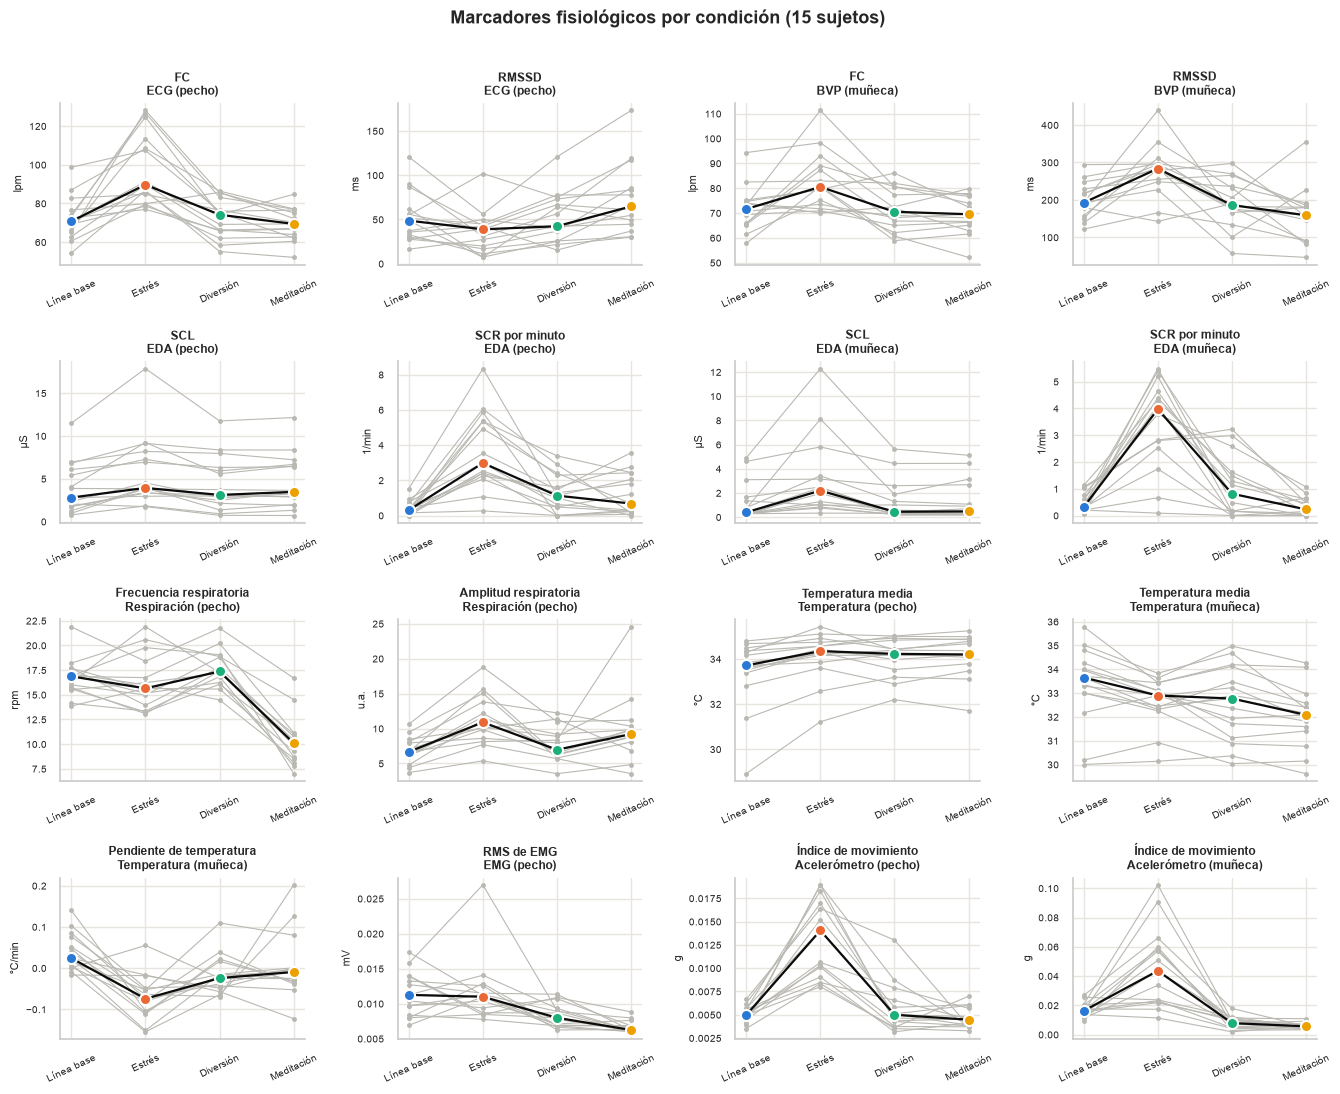

In [3]:
items = [("chest_ECG", "FC"), ("chest_ECG", "RMSSD"), ("wrist_BVP", "FC"), ("wrist_BVP", "RMSSD"),
         ("chest_EDA", "SCL"), ("chest_EDA", "SCR por minuto"), ("wrist_EDA", "SCL"), ("wrist_EDA", "SCR por minuto"),
         ("chest_Resp", "Frecuencia respiratoria"), ("chest_Resp", "Amplitud respiratoria"),
         ("chest_Temp", "Temperatura media"), ("wrist_TEMP", "Temperatura media"),
         ("wrist_TEMP", "Pendiente de temperatura"), ("chest_EMG", "RMS de EMG"),
         ("chest_ACC", "Índice de movimiento"), ("wrist_ACC", "Índice de movimiento")]
fig = gr.plot_markers_by_condition(markers, items, title="Marcadores fisiológicos por condición (15 sujetos)")
gr.savefig(fig, "04_marcadores_por_condicion"); plt.show()

### ⚠ Cuidado con la variabilidad cardíaca (RMSSD, SDNN, pNN50) del BVP de muñeca
Los valores de RMSSD del BVP (cientos de ms) son **mucho mayores** que los del ECG (decenas de ms). No es fisiología:
el BVP de muñeca se mueve con el brazo y el detector a veces confunde el ruido con un latido (o se salta uno), y
cada error de ese tipo infla las diferencias entre latidos. Por eso, aunque salgan "significativos" en las
pruebas de abajo, **las métricas de HRV del BVP no deben interpretarse como HRV real**; reflejan sobre todo
movimiento (que es mayor en el estrés). La frecuencia cardíaca media del BVP sí es útil en reposo (sección 6).

## 3. Pruebas estadísticas: ¿qué marcadores cambian de verdad?
Con 15 personas que pasan por todas las condiciones usamos pruebas **no paramétricas y pareadas**:
- **Friedman**: ¿hay diferencias entre línea base, estrés y diversión? `kendall_W` es el tamaño del efecto
  (0 = nada, 1 = todos los sujetos ordenan las condiciones igual).
- **Wilcoxon** por pares, con corrección de **Holm** por hacer varias comparaciones.
- **r (rango-biserial)**: tamaño del efecto de cada par, de −1 a 1. Positivo = el valor es mayor en la segunda
  condición. Como guía: |r| ≈ 0.1 pequeño, 0.3 mediano, ≥ 0.5 grande.

Se usa **un valor por sujeto y condición**, no miles de ventanas, para no inflar la significancia.
La tabla está ordenada por el efecto línea base → estrés.

In [4]:
comp = estadistica.compare_conditions(markers)
comp = comp.reindex(comp["r_baseline_vs_stress"].abs().sort_values(ascending=False).index)
comp.to_csv(os.path.join(cfg.OUT_DIRS["tables"], "pruebas_por_marcador.csv"), index=False)
cols = ["señal", "marcador", "unidad", "n_sujetos", "mediana_baseline", "mediana_stress", "mediana_amusement",
        "friedman_p", "kendall_W", "r_baseline_vs_stress", "p_holm_baseline_vs_stress", "r_stress_vs_amusement",
        "p_holm_stress_vs_amusement"]
comp[cols].round(3)

,señal,marcador,unidad,n_sujetos,mediana_baseline,mediana_stress,mediana_amusement,friedman_p,kendall_W,r_baseline_vs_stress,p_holm_baseline_vs_stress,r_stress_vs_amusement,p_holm_stress_vs_amusement
0,chest_ACC,Índice de movimiento,g,15,0.005,0.014,0.005,0.000,0.751,1.000,0.000,-1.000,0.000
2,chest_ECG,FC,lpm,15,70.787,89.716,74.158,0.000,0.658,1.000,0.000,-0.983,0.000
8,chest_EDA,SCR por minuto,1/min,15,0.305,2.982,1.129,0.000,0.781,1.000,0.000,-1.000,0.000
19,wrist_BVP,SDNN,ms,14,158.600,232.202,153.300,0.000,0.648,1.000,0.000,-0.943,0.001
14,chest_Temp,Temperatura media,°C,15,33.711,34.346,34.224,0.000,0.653,1.000,0.000,-0.100,0.762
10,chest_Resp,Amplitud respiratoria,u.a.,15,6.666,10.894,6.964,0.000,0.698,1.000,0.000,-0.917,0.001
23,wrist_EDA,SCR por minuto,1/min,15,0.315,3.971,0.815,0.000,0.520,0.983,0.000,-0.917,0.001
24,wrist_TEMP,Pendiente de temperatura,°C/min,15,0.024,-0.074,-0.024,0.000,0.551,-0.950,0.001,0.683,0.018
22,wrist_EDA,SCL,µS,15,0.399,2.196,0.444,0.000,0.573,0.950,0.001,-0.967,0.001
7,chest_EDA,SCL,µS,15,2.806,3.933,3.113,0.000,0.591,0.933,0.001,-0.983,0.000


**Mapa de efectos.** Cada fila es un marcador; las columnas son las comparaciones. Rojo = el marcador sube en la
segunda condición; azul = baja. Los asteriscos marcan p < 0.05 tras la corrección de Holm. Los marcadores con
color intenso en **Línea base → Estrés** y en **Estrés → Diversión** son los mejores candidatos para el modelo:
distinguen el estrés tanto del reposo como de otra emoción activadora.

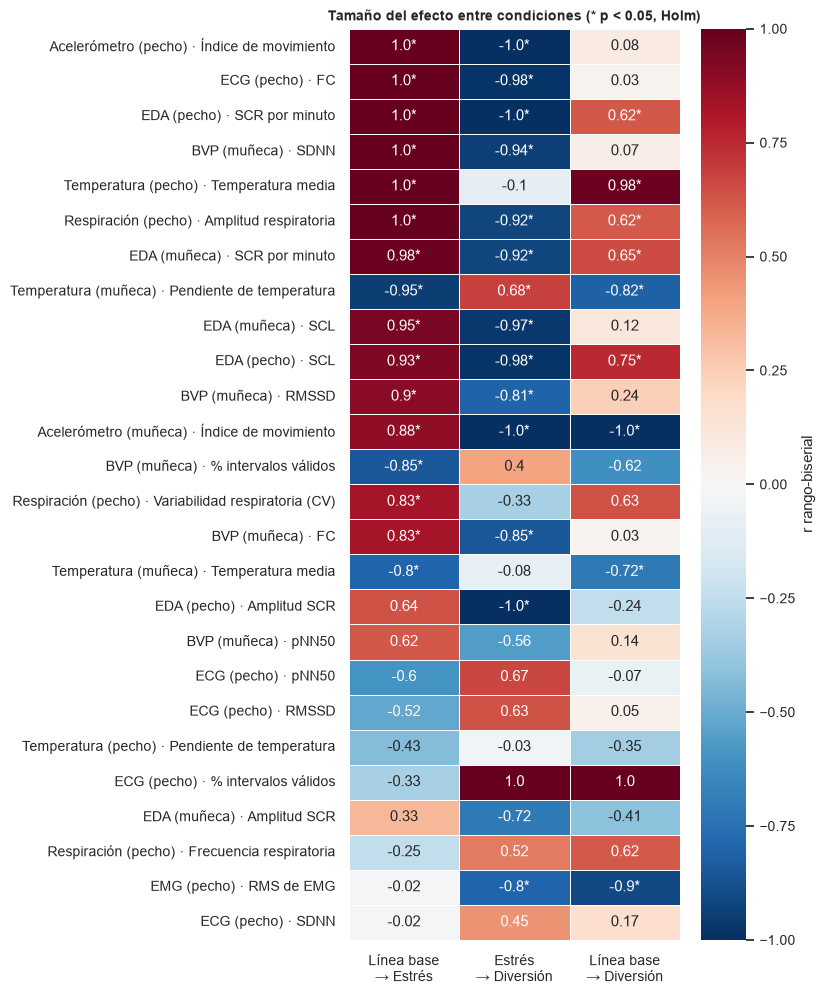

In [5]:
pairs = [("baseline", "stress"), ("stress", "amusement"), ("baseline", "amusement")]
eff = comp.set_index(comp.señal.map(lambda k: cfg.SIGNALS[k]["name"]) + " · " + comp.marcador)
R = eff[[f"r_{a}_vs_{b}" for a, b in pairs]]; P = eff[[f"p_holm_{a}_vs_{b}" for a, b in pairs]]
annot = R.round(2).astype(str).values + np.where(P.values < 0.05, "*", "")
fig, ax = plt.subplots(figsize=(8, 0.33 * len(R) + 1.5))
sns.heatmap(R, cmap="RdBu_r", vmin=-1, vmax=1, annot=annot, fmt="", linewidths=0.5, linecolor="white",
            cbar_kws={"label": "r rango-biserial"}, ax=ax)
ax.set_xticklabels([f"{gr.COND_ES[a]}\n→ {gr.COND_ES[b]}" for a, b in pairs], rotation=0)
ax.set_ylabel(""); ax.set_title("Tamaño del efecto entre condiciones (* p < 0.05, Holm)")
fig.tight_layout(); gr.savefig(fig, "04_mapa_efectos"); plt.show()

## 4. ¿Respondió cada sujeto al estrés?
Cambio de frecuencia cardíaca (ECG) y de SCL (EDA de pecho) del estrés respecto a la línea base, sujeto por sujeto,
junto con las notas del investigador. Ayuda a entender por qué el modelo podría fallar con algunos participantes.

In [6]:
def delta(sig, mk):
    w = markers[(markers.señal == sig) & (markers.marcador == mk)].pivot(index="sujeto", columns="condicion", values="valor")
    return w["stress"] - w["baseline"]
resp = pd.DataFrame({"Δ FC ECG (lpm)": delta("chest_ECG", "FC"), "Δ RMSSD ECG (ms)": delta("chest_ECG", "RMSSD"),
                     "Δ SCL pecho (µS)": delta("chest_EDA", "SCL"), "Δ SCL muñeca (µS)": delta("wrist_EDA", "SCL"),
                     "Δ frec. resp. (rpm)": delta("chest_Resp", "Frecuencia respiratoria")})
resp = resp.loc[sorted(resp.index, key=gr.subject_sort_key)]
resp["nota del investigador"] = [carga.read_notes(DATA_PATH, int(s[1:])) for s in resp.index]
resp.round(2)

,Δ FC ECG (lpm),Δ RMSSD ECG (ms),Δ SCL pecho (µS),Δ SCL muñeca (µS),Δ frec. resp. (rpm),nota del investigador
sujeto,,,,,,
S2,4.43,-16.92,-0.30,0.58,-3.48,The RespiBAN temperature sensor was not fully ...
S3,32.30,-64.56,1.23,0.84,-0.78,"During the baseline condition, the subject was..."
S4,19.08,-44.43,2.65,2.06,2.38,
S5,26.89,-13.23,5.15,2.64,0.71,Subject might have fallen asleep during the fi...
S6,9.38,12.60,2.31,7.42,-1.03,Subject claimed that he had a stressfull week ...
S7,15.56,47.15,6.38,1.20,2.87,
S8,20.50,-6.49,-0.04,0.41,-1.85,"Subject had already a rather stressful day, pr..."
S9,3.27,6.75,1.58,0.79,1.78,
S10,8.68,10.84,1.04,2.03,-3.76,


## 5. Variabilidad entre personas
El coeficiente de variación (CV) entre sujetos en la línea base indica cuánto difiere el "nivel normal" de una
persona a otra. Un CV alto (p. ej. > 30 %) significa que el valor absoluto dice poco sin saber de quién es:
**por eso se normaliza por sujeto** (etapa 7 del pipeline, Nkurikiyeyezu et al. 2019).

In [7]:
cv = estadistica.between_subject_cv(markers).sort_values("cv_entre_sujetos_pct", ascending=False)
cv["señal"] = cv.señal.map(lambda k: cfg.SIGNALS[k]["name"])
cv.round(1)

,señal,marcador,cv_entre_sujetos_pct
6,EDA (pecho),Amplitud SCR,149.0
22,EDA (muñeca),SCL,124.9
24,Temperatura (muñeca),Pendiente de temperatura,113.7
21,EDA (muñeca),Amplitud SCR,107.9
8,EDA (pecho),SCR por minuto,100.6
13,Temperatura (pecho),Pendiente de temperatura,77.8
7,EDA (pecho),SCL,76.3
5,ECG (pecho),pNN50,75.6
23,EDA (muñeca),SCR por minuto,69.6
3,ECG (pecho),RMSSD,54.8


## 6. Concordancia entre sensores que miden lo mismo
- **Frecuencia cardíaca ECG vs. BVP**: análisis de Bland-Altman. Muestra el **sesgo** (diferencia promedio) y los
  **límites de acuerdo** (entre qué valores cae el 95 % de las diferencias). Si los límites son estrechos
  (p. ej. ±5 lpm), el BVP de muñeca puede reemplazar al ECG para la frecuencia cardíaca.
- **SCL pecho vs. muñeca**: correlación de Spearman entre sujetos y condiciones. Los dos sensores están en sitios
  distintos (abdomen y muñeca), así que no se espera que coincidan en valor, pero sí en tendencia.

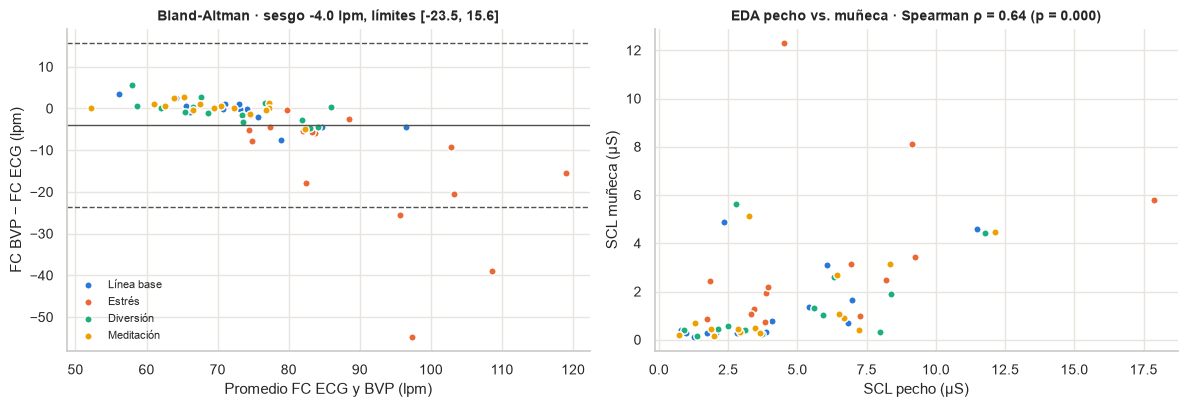

In [8]:
from scipy.stats import spearmanr
hr = markers[markers.marcador == "FC"].pivot_table(index=["sujeto", "condicion"], columns="señal", values="valor").dropna()
ba = estadistica.bland_altman(hr["wrist_BVP"], hr["chest_ECG"])
eda = markers[markers.marcador == "SCL"].pivot_table(index=["sujeto", "condicion"], columns="señal", values="valor").dropna()
rho, p_rho = spearmanr(eda["chest_EDA"], eda["wrist_EDA"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
mean_ = (hr["wrist_BVP"] + hr["chest_ECG"]) / 2; diff_ = hr["wrist_BVP"] - hr["chest_ECG"]
conds = hr.index.get_level_values("condicion")
for c in cfg.COND_ORDER:
    m = conds == c
    axes[0].scatter(mean_[m], diff_[m], color=gr.COND_COLORS[c], s=28, label=gr.COND_ES[c], edgecolor="white")
for v, ls in ((ba["sesgo"], "-"), (ba["lim_inf"], "--"), (ba["lim_sup"], "--")):
    axes[0].axhline(v, color="#52514e", lw=1, ls=ls)
axes[0].set_xlabel("Promedio FC ECG y BVP (lpm)"); axes[0].set_ylabel("FC BVP − FC ECG (lpm)")
axes[0].set_title(f"Bland-Altman · sesgo {ba['sesgo']:.1f} lpm, límites [{ba['lim_inf']:.1f}, {ba['lim_sup']:.1f}]")
axes[0].legend(frameon=False, fontsize=8)
conds = eda.index.get_level_values("condicion")
for c in cfg.COND_ORDER:
    m = conds == c
    axes[1].scatter(eda["chest_EDA"][m], eda["wrist_EDA"][m], color=gr.COND_COLORS[c], s=28, edgecolor="white")
axes[1].set_xlabel("SCL pecho (µS)"); axes[1].set_ylabel("SCL muñeca (µS)")
axes[1].set_title(f"EDA pecho vs. muñeca · Spearman ρ = {rho:.2f} (p = {p_rho:.3f})")
fig.tight_layout(); gr.savefig(fig, "04_concordancia_sensores"); plt.show()

## 📌 Qué encontramos con los datos reales
**Marcadores que separan el estrés de la línea base y de la diversión** (efecto grande y p < 0.05 con Holm en ambas comparaciones):
- **Frecuencia cardíaca (ECG):** 70.8 → 89.7 lpm (r = 1.00).
- **SCR por minuto:** pecho 0.3 → 3.0 y muñeca 0.3 → 4.0.
- **SCL:** pecho 2.8 → 3.9 µS y muñeca 0.40 → 2.20 µS.
- **Amplitud respiratoria:** 6.7 → 10.9.
- **Pendiente de temperatura de muñeca:** 0.02 → −0.07 °C/min (se enfría durante el estrés).

**Lo que no funcionó como se esperaba:**
- **RMSSD del ECG** baja (48.7 → 38.9 ms) pero no es significativo tras la corrección (p = 0.17): la HRV varía mucho entre personas.
- **Frecuencia respiratoria** no sube en el estrés (16.9 → 15.6 rpm). El TSST obliga a hablar, y al hablar se respira
  distinto: sube la amplitud y la irregularidad, no la frecuencia. En meditación baja a 10 rpm, como se espera.
- **Temperatura de pecho** es más alta en todas las condiciones posteriores a la línea base, sin una respuesta propia
  al estrés (no distingue estrés de diversión); probablemente refleja el calentamiento del sensor contra la piel.
- **HRV del BVP:** valores no fisiológicos (ver advertencia arriba).

**Concordancia:** la FC del BVP coincide con la del ECG en reposo (±5 lpm), pero en el estrés la subestima
(límites de acuerdo −23.5 a +15.6 lpm). La EDA de pecho y la de muñeca siguen la misma tendencia (ρ = 0.64).

**Variabilidad entre personas:** el SCL, las SCR y la HRV varían más del 50 % entre sujetos en la línea base, lo que
justifica normalizar por sujeto.

## Resumen de este notebook
- Tablas en `salidas/tablas/marcadores_por_condicion.csv` y `pruebas_por_marcador.csv` (para el capítulo).
- Siguiente paso: **05_ventanas_y_exportacion**, que deja los datos listos para el objetivo 2.